### Tutorial 6 -- Brown dwarfs modelling 

Similar to Tutorial 1, but for the brown dwarfs (ATMO models). 

In [ ]:

import numpy as np 

from jjmodel.constants import tp
from jjmodel.input_ import p, a, inp
from jjmodel.funcs import IMF
from jjmodel.mwdisk import disk_builder
from jjmodel.populations import StellarAssemblies
from jjmodel.analysis import GetPopulations
from jjmodel.plotting import Plotting



Parameter file(s) : ok.
Number of parameters =  66 , among them technical =  7

 p(run_mode=0, out_dir='test1', out_mode=0, nprocess=16, Rsun=8.2, zsun=20, zmax=2000, dz=2, sigmad=31.2, sigmat=4.9, sigmag1=1.7, sigmag2=10.9, sigmadh=51.9, sigmash=0.47, td1=0, td2=7.8, dzeta=0.58, eta=5.02, pkey=1, tt1=0.1, tt2=4, gamma=2, beta=3.5, imfkey=0, a0=1.04, a1=1.61, a2=2.94, a3=2.28, m0=0.5, m1=1.5, m2=6.0, dFeHdt=0, n_FeHdt=1, fehkey=0, FeHd0=-0.7, FeHdp=0.29, rd=0.34, q=-0.72, FeHt0=-0.94, FeHtp=0.04, rt=0.77, t0=0.97, FeHsh=-1.5, dFeHsh=0.4, n_FeHsh=5, alpha=0.409, sige=26.0, sigt=45, sigdh=140, sigsh=100, sigmap=array([3.5, 1.3]), tpk=array([10. , 12.5]), dtp=array([0.7 , 0.25]), sigp=array([26.3, 12.6]))

Parameters checked: 0 Reminders, 0 Warnings, 0 Errors.

Configuration finished:  0h 0m 0.01s


#### Running the core module of the model

Constructed the disk model by calling the ```disk_builder()``` function. 
For details, see Tutorial 1. 

In [2]:

# Run the model
disk_builder(p,a,inp,status_progress=True)


Results of this run will be saved to  output/Rsun8.2_test1 


Output directory tree created.

---Local run---

  Process for R = 8.2 kpc: start       
    Process for R = 8.2 kpc: fimax optimized
      Process for R = 8.2 kpc: PE solved   
        Process 8.2   : exit, time: 0h 0m 0.16s


Input data saved.

Output data saved.

---Local run ended sucessfully---



#### Creating mock stellar populations

Use kyeword ```bd``` (brown dwarfs) in ```mode_iso```. Note that it is currently only possible to model brown dwarfs separately from other populations as ATMO models do not provide photometric bands common with the main sequence/giant/white dwrfs populations. 

For the brown dwarfs, you have the following options: 

- ```ATMO_CEQ``` with two alternative photometric sets, ```MKO_WISE_IRAC``` and ```NIRCAM``` (mod A)
- ```ATMO_NEQ``` with ```MKO_WISE_IRAC```

These models are described in [Phillips et al. (2020)](https://arxiv.org/pdf/2003.13717). 

In [ ]:
# IMF 
# Important for brown dwarfs: 
# - set a mlow to include low-mass dwarfs
# - increase mass resolution for reliable computation of counts
imf = IMF(mlow=0.0001,mres=0.0001)        
mass, Nmdm = imf.BPL_4slopes(p.a0,p.a1,p.a2,p.a3,p.m0,p.m1,p.m2)

# Isochrone grid and photometry
mode_iso = {'bd':'ATMO_CEQ'}
photometric_system = 'MKO_WISE_IRAC'
mode_label = '-'.join(mode_iso.values())

# MW components to populate - tnin/thick disk and stellar halo
mw_comp = ['d', 't', 'sh']

# Produce SA table (separate for the thin and thick disk and halo), 
# stored in /output/your_main_name/pop/tab 

sa = StellarAssemblies(p,a,mode_iso,photometric_system) 

sa.create_pops(
    p.Rsun,
    inp['AMRd0'],   # age-metallicity relation (thin disk)
    inp['AMRt'],    # age-metallicity relation (thick disk)
    inp['SFRd0'],   # star formation rate (thin disk)
    inp['SFRt0'],   # star formation rate (thick disk)
    p.sigmash,      # present-day halo surface density (up to 2 kpc)
    imf.number_stars
    );

#### Select populations

You can choose different populations to analyse - e.g., L, T, or Y dwarfs. 

In [4]:

pop = GetPopulations(mode_iso, p.Rsun, p, a)

print(f'R = {p.Rsun} kpc')

# Population selection methods
methods = [
    pop.l_dwarfs,
    pop.t_dwarfs,
    pop.y_dwarfs,
]

kwgs = {'save': True}
for comp in mw_comp:
    for method in methods:
        method(comp, **kwgs)


R = 8.2 kpc


#### Plotting

The rest of this tutorial is about plotting the model input and output. 

You can analyse data tables in the output directory and create your own plots. 
Here we use an in-built plotting tool of the *jjmodel* package. They allow to get a quick look at interesting quantities. 

Before we proceed, it is useful to remind some notations:

    MW stellar components:                          Stellar populations:
    'd'   = thin disk                               'a'            = A stars 
    't'   = thick disk                              'f'            = F stars
    'sh'  = stellar halo                            'rc' or 'rc+'  = RC stars
    'dt'  = thin + thick disk                       'gdw'          = G dwarfs
    'tot' = thin + thick disk + stellar halo        'kdw'          = K dwarfs
                                                    'wd'           = White dwarfs
                                                    'ldw'          = L dwarfs
                                                    'tdw'          = T dwarfs
                                                    'ydw'          = Y dwarfs

Note that some input and output quantities, such as the mass loss function $g$ 
or vertical force $K_z$ (see the next block below), are not given via analytic form,
but are instead calculated on the grid, and therefore, look step-like.

Each method of the class ```Plotting``` returns *matplotlib* figure and axes, so it's possible to customise the plot. 

##### Input functions: SFR, AMR, mass loss

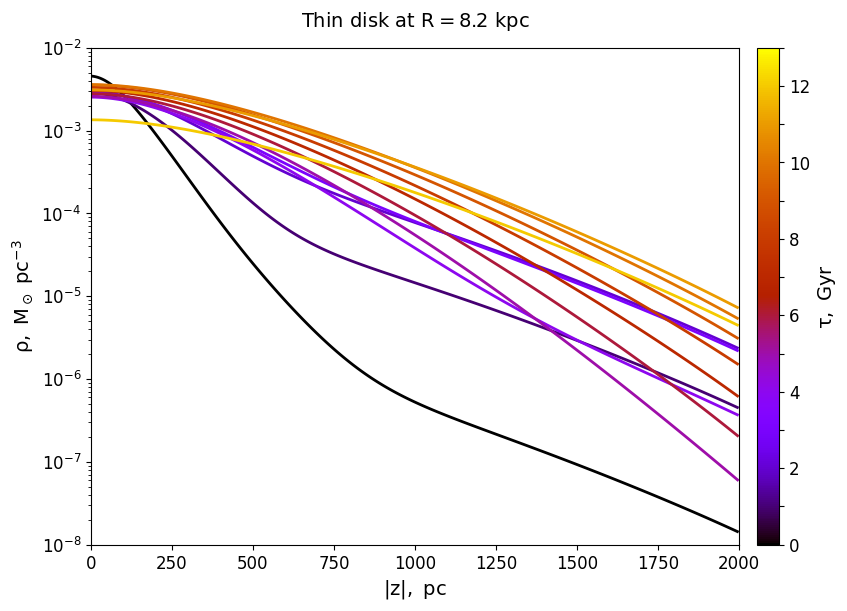

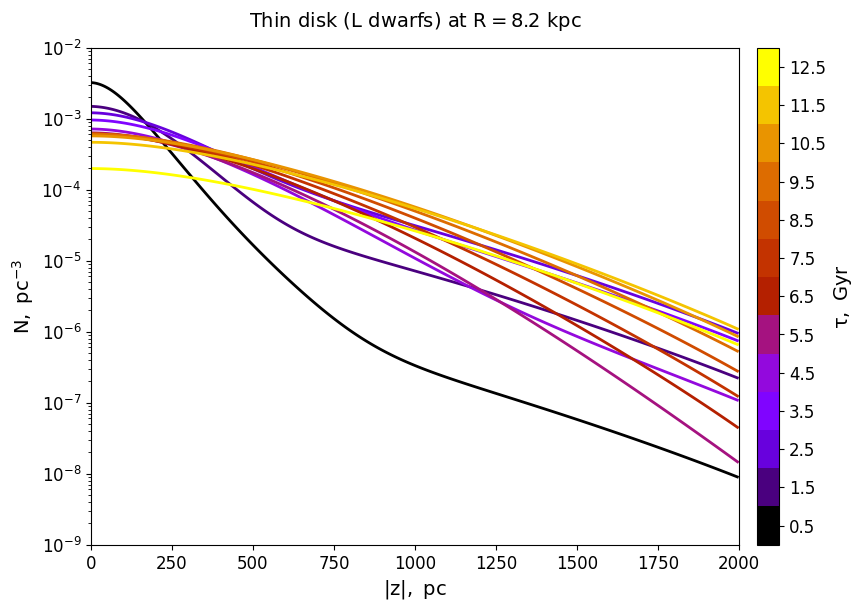

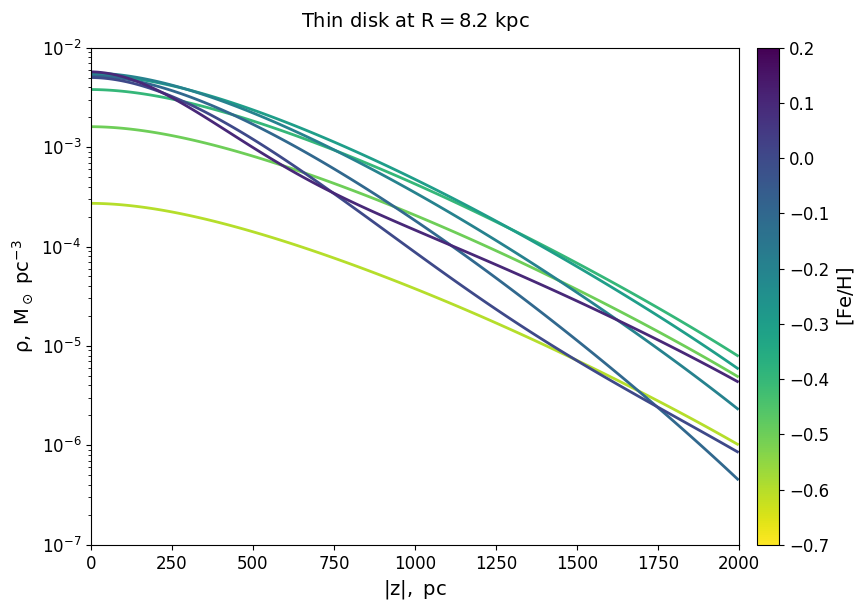

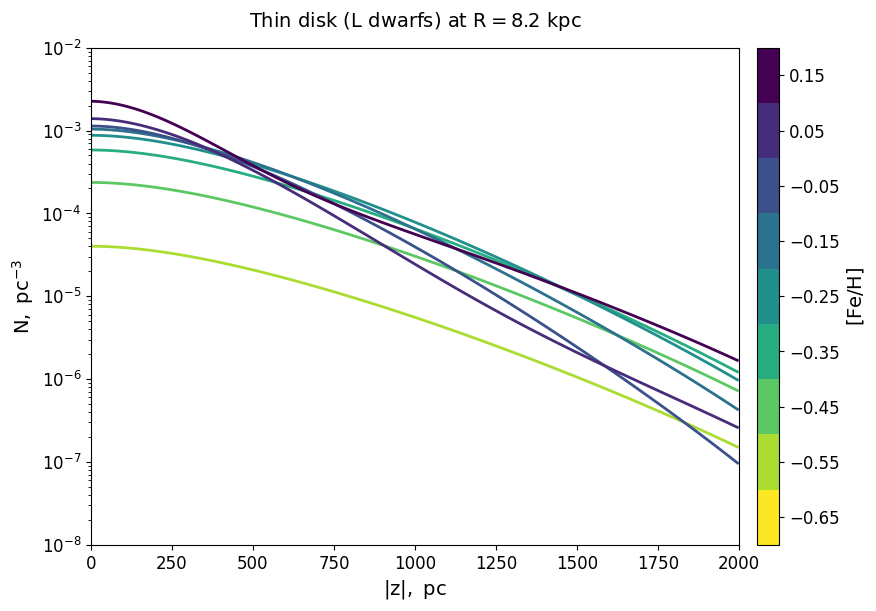

In [12]:

P = Plotting(p,a,inp)

# Density laws for the mono- age/metallicity populations
ages = np.arange(0,tp + 1, 1)      # Gyr, custom age bins
mets = np.arange(-0.7,0.3,0.1)     # dex, metallicity bins

kw = {'mode_iso':mode_iso}

P.rhoz_monoage_plt('d',p.Rsun,ages,between=True)   
P.rhoz_monoage_plt('d',p.Rsun,ages,cbar_bins=True,between=True,mode_pop='ldw',number=True,**kw);

P.rhoz_monomet_plt('d',p.Rsun,mets,cbar='viridis_r')   
P.rhoz_monomet_plt('d',p.Rsun,mets,cbar_bins=True,cbar='viridis_r',mode_pop='ldw',number=True,**kw);


#### Age gradients and distributions

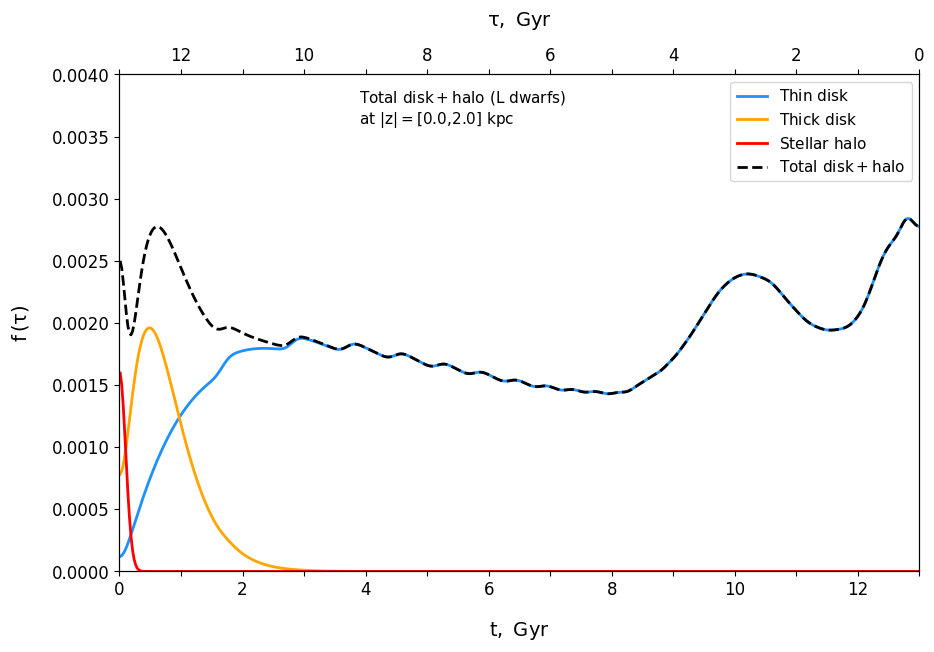

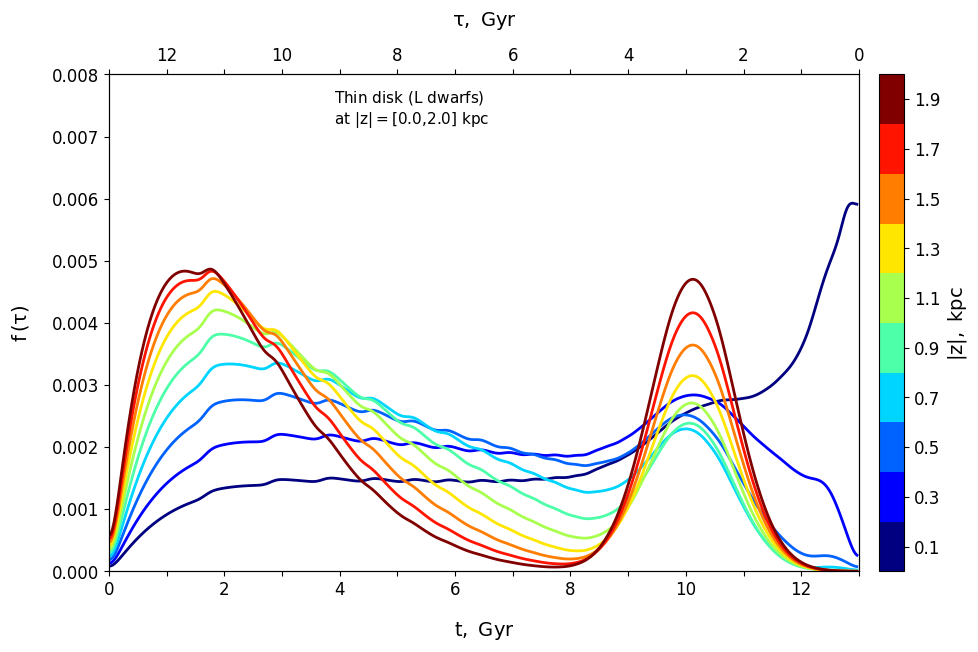

In [15]:

# Age distribution
# Try 'cumulative=True'; parameter 'sigma_gauss' (in Gyr) adds Gaussian smoothing
z_range = [0,2000]  # pc, limit in height 
P.agehist_rsun_plt('tot',z_range,mode_pop='ldw',number=True,sigma_gauss=0.1,**kw)

# To see how age distributions change with height, give z-bins instead of a range of z:
z_slices = np.arange(0, p.zmax + 200, 200)  # pc
P.agehist_rsun_plt('d',z_slices,sigma_gauss=0.1,cbar_bins=True,mode_pop='ldw',number=True,**kw);


#### W-velocity distributions

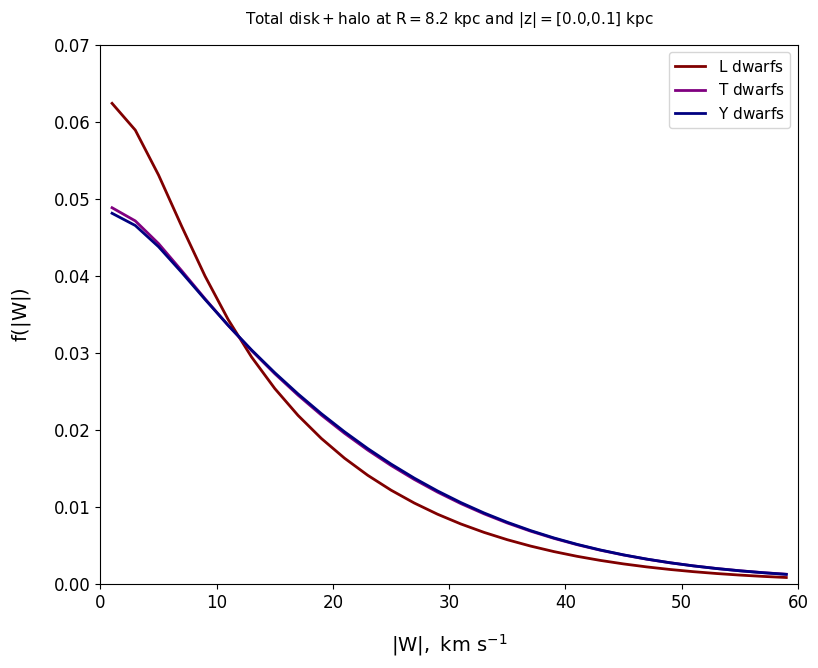

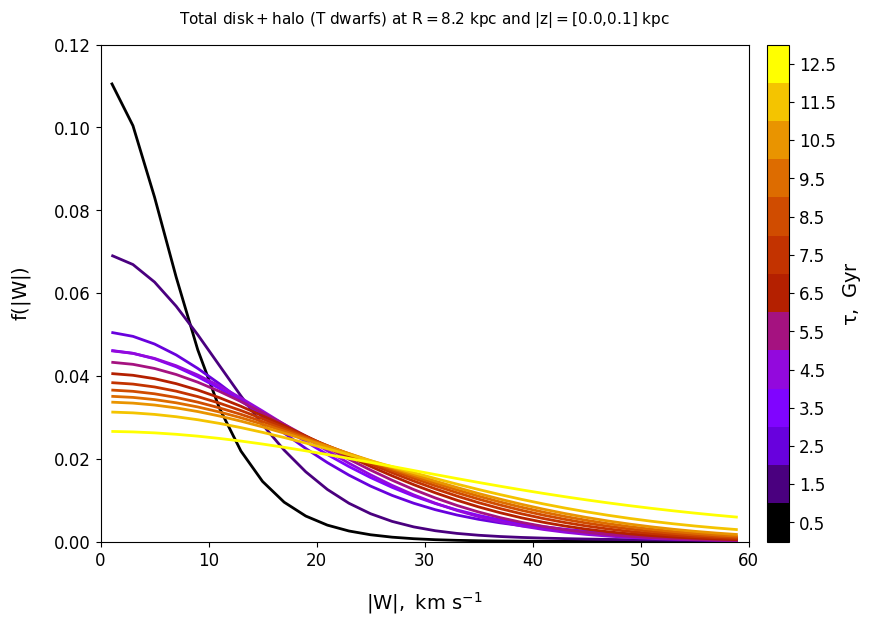

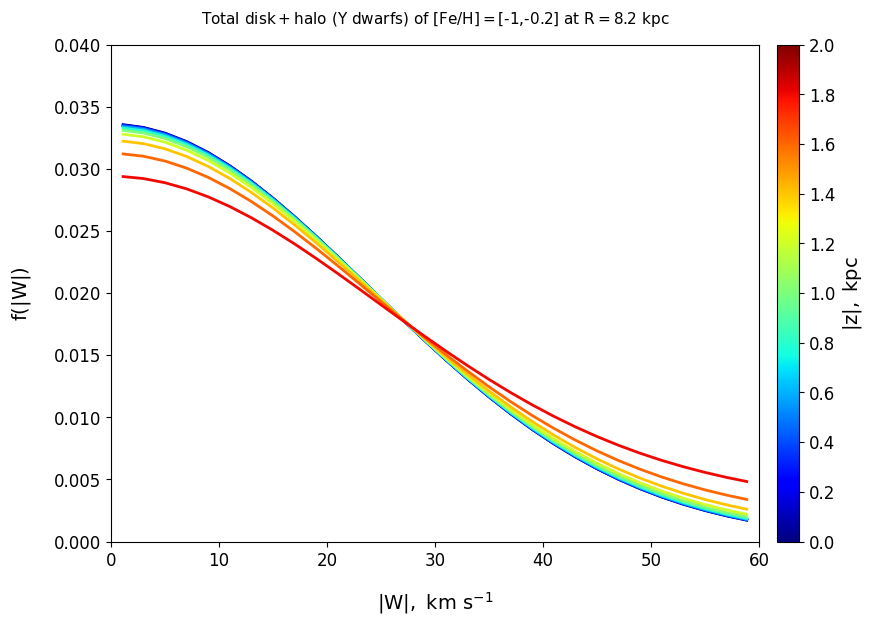

In [16]:

z_range = [0, 100] # pc, a range of height
pop_list = ['ldw','tdw','ydw']

# Velocity distribution of the defined populations in the selected z-slice
P.fw_hist_plt('tot',p.Rsun,z_range,mode_pop=pop_list,number=True,**kw)

# f(|W|) for age bins can be plotted if keyword 'ages' is used:
age_bins = np.arange(0, tp + 1, 1) # Gyr, age bins
P.fw_hist_plt('tot',p.Rsun,z_range,ages=age_bins,mode_pop='tdw',number=True,cbar_bins=True,**kw)

# Also, metallicity interval can be chosen (metallicity bins with z_range),
# and f(|W|) in the different z-bins can be calculated: 
met_range = [-1,-0.2]  # Gyr
z_slices = np.arange(0, p.zmax + 200, 200)  # pc
P.fw_hist_plt('tot',p.Rsun,z_slices,mode_pop='ydw',number=True,mets=met_range,**kw);


#### Hess diagram

We can model two types of the local volume: 

- sphere (with an inner hole if needed, use parameter ```r_minmax```). Additionally, $z$-cut can be applied to this volume (parameter ```zlim```).
- cylinder (inner cylinder can be cut out by setting 0-th element of ```r_minmax``` to $>0$). 

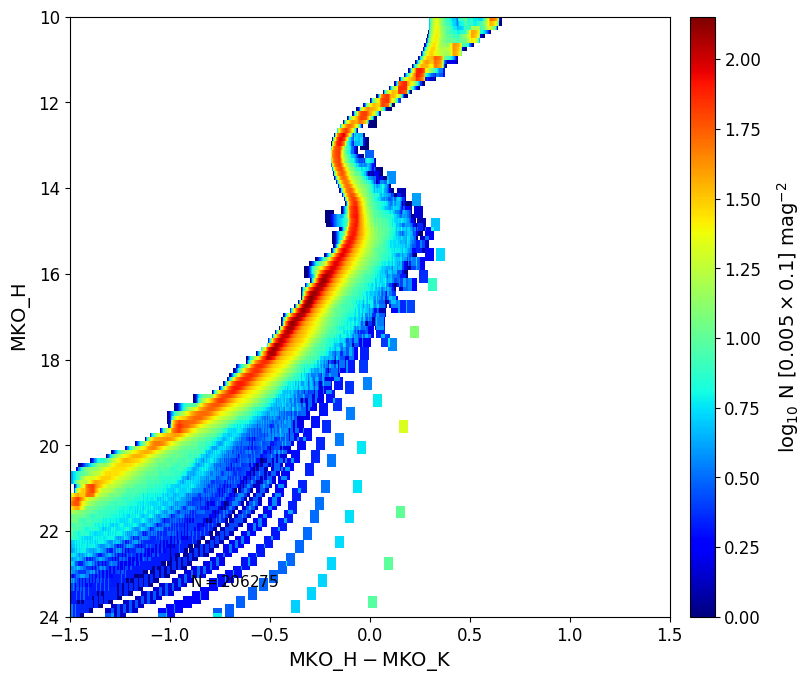

In [17]:

# Sphere
kw = {'mode_iso':mode_iso,'save':True} #  'mode_pop':'ydw' for specific populations

r_inn = 0   # pc 
r_out = 100  # pc

P.hess_simple_plt(
    'tot',                                          # MW components to include
    'local_sphere',                                 # type of volume
    ['MKO_H','MKO_H','MKO_K'],                      # photometric columns, y=c1, x=c2-c3
    [[-1.5,1.5],[10,24]],                           # range in x and y 
    [0.005,0.1],                                    # resolution in x and y
    smooth=[0.05,0.3],                              # smoothing in x and y 
    r_minmax=[r_inn,r_out],                         # inner and outer radii
    **kw        
    );
